# گام سوم پروژه: EDA دیتاست MovieLens

این نوت‌بوک تحلیل اکتشافی داده‌ها را روی دیتاست MovieLens `ml-latest-small` انجام می‌دهد. ابتدا کیفیت داده خام و داده پاک‌سازی‌شده بررسی می‌شود؛ سپس نوع ویژگی‌ها، آمار توصیفی، توزیع امتیازها، فعالیت کاربران، محبوبیت فیلم‌ها و ژانرها تحلیل می‌شوند.

**پیش‌نیاز:** فایل‌های مرحله آماده‌سازی باید در `data/raw/` و `data/processed/` وجود داشته باشند. اگر خروجی‌های پردازش‌شده وجود نداشته باشند، نوت‌بوک اسکریپت آماده‌سازی پروژه را اجرا می‌کند.


In [12]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project root whether Jupyter starts in the project root or notebooks/.
candidates = [Path.cwd(), *Path.cwd().parents[:3]]
PROJECT_ROOT = next(
    (p for p in candidates if (p / "scripts" / "prepare_movielens.py").exists()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Open this notebook from the step2_movielens folder "
        "or its notebooks subfolder."
    )

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ml-latest-small"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

if (not (RAW_DIR / "ratings.csv").exists()
        or not (PROCESSED_DIR / "ratings_clean.csv").exists()):
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
    from prepare_movielens import prepare_movielens
    prepare_movielens(PROJECT_ROOT)

print("Project root:", PROJECT_ROOT)
print("Raw data folder exists:", RAW_DIR.exists())
print("Processed data folder exists:", PROCESSED_DIR.exists())


Project root: c:\Users\Mobin iT\Desktop\movie-book-recommender-ai\step2_movielens
Raw data folder exists: True
Processed data folder exists: True


In [13]:
# Load raw files to inspect data quality before cleaning.
ratings_raw = pd.read_csv(RAW_DIR / "ratings.csv")
movies_raw = pd.read_csv(RAW_DIR / "movies.csv")

# Load prepared files for the main analysis.
ratings = pd.read_csv(PROCESSED_DIR / "ratings_clean.csv")
movies = pd.read_csv(PROCESSED_DIR / "movies_clean.csv")
train = pd.read_csv(PROCESSED_DIR / "train.csv")
test = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Raw ratings:", ratings_raw.shape)
print("Raw movies:", movies_raw.shape)
print("Clean ratings:", ratings.shape)
print("Clean movies:", movies.shape)
print("Train:", train.shape)
print("Test:", test.shape)

display(ratings.head())
display(movies.head())


Raw ratings: (100836, 4)
Raw movies: (9742, 3)
Clean ratings: (100836, 4)
Clean movies: (9742, 3)
Train: (80419, 6)
Test: (20417, 6)


,userId,movieId,rating,timestamp
0,1,804,4.0,964980499
1,1,1210,5.0,964980499
2,1,2018,5.0,964980523
3,1,2628,4.0,964980523
4,1,2826,4.0,964980523


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## 1. شناخت اولیه و نوع ویژگی‌ها

شناسه‌های `userId` و `movieId` عددی هستند، اما متغیر کمی پیوسته محسوب نمی‌شوند؛ آن‌ها فقط شناسه‌اند. امتیاز `rating` یک ویژگی عددی ترتیبی است. `timestamp` زمان ثبت امتیاز را نشان می‌دهد و `genres` یک ویژگی دسته‌ای چندبرچسبی است.


In [14]:
feature_types = pd.DataFrame([
    ["userId", "شناسه کاربر", "شناسه‌ای / دسته‌ای"],
    ["movieId", "شناسه فیلم", "شناسه‌ای / دسته‌ای"],
    ["rating", "امتیاز کاربر به فیلم (۰٫۵ تا ۵)", "عددی ترتیبی"],
    ["timestamp", "زمان ثبت امتیاز (Unix)", "زمانی"],
    ["title", "عنوان فیلم", "متنی"],
    ["genres", "ژانرهای فیلم با جداکننده |", "دسته‌ای چندبرچسبی"],
], columns=["feature", "meaning", "data_type"])
display(feature_types)

print("\nData types in raw ratings:")
display(ratings_raw.dtypes.to_frame("dtype"))
print("\nData types in cleaned ratings:")
display(ratings.dtypes.to_frame("dtype"))


,feature,meaning,data_type
0,userId,شناسه کاربر,شناسه‌ای / دسته‌ای
1,movieId,شناسه فیلم,شناسه‌ای / دسته‌ای
2,rating,امتیاز کاربر به فیلم (۰٫۵ تا ۵),عددی ترتیبی
3,timestamp,زمان ثبت امتیاز (Unix),زمانی
4,title,عنوان فیلم,متنی
5,genres,ژانرهای فیلم با جداکننده |,دسته‌ای چندبرچسبی



Data types in raw ratings:


,dtype
userId,int64
movieId,int64
rating,float64
timestamp,int64



Data types in cleaned ratings:


,dtype
userId,int64
movieId,int64
rating,float64
timestamp,int64


## 2. بررسی کیفیت داده‌ها: مقادیر گمشده و تکراری

هم داده خام و هم داده پاک‌سازی‌شده بررسی می‌شوند. علاوه بر ردیف‌های کاملاً تکراری، تکرار کلید ترکیبی `(userId, movieId)` نیز بررسی می‌شود؛ چون در پروژه هر کاربر-فیلم باید پس از پاک‌سازی یک رکورد داشته باشد.


In [15]:
def quality_summary(name, frame, duplicate_key=None):
    result = {
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "missing_cells": int(frame.isna().sum().sum()),
        "exact_duplicate_rows": int(frame.duplicated().sum()),
    }
    if duplicate_key:
        result["duplicate_key_rows"] = int(
            frame.duplicated(duplicate_key, keep=False).sum()
        )
        result["duplicate_key_groups"] = int(
            frame.groupby(duplicate_key, dropna=False).size().gt(1).sum()
        )
    return result

quality = pd.DataFrame([
    quality_summary("ratings_raw", ratings_raw, ["userId", "movieId"]),
    quality_summary("movies_raw", movies_raw, ["movieId"]),
    quality_summary("ratings_clean", ratings, ["userId", "movieId"]),
    quality_summary("movies_clean", movies, ["movieId"]),
    quality_summary("train", train, ["userId", "movieId"]),
    quality_summary("test", test, ["userId", "movieId"]),
])
display(quality)

print("Missing values by column — raw ratings:")
display(ratings_raw.isna().sum().to_frame("missing"))
print("Missing values by column — raw movies:")
display(movies_raw.isna().sum().to_frame("missing"))


,dataset,rows,columns,missing_cells,exact_duplicate_rows,duplicate_key_rows,duplicate_key_groups
0,ratings_raw,100836,4,0,0,0,0
1,movies_raw,9742,3,0,0,0,0
2,ratings_clean,100836,4,0,0,0,0
3,movies_clean,9742,3,0,0,0,0
4,train,80419,6,0,0,0,0
5,test,20417,6,0,0,0,0


Missing values by column — raw ratings:


,missing
userId,0
movieId,0
rating,0
timestamp,0


Missing values by column — raw movies:


,missing
movieId,0
title,0
genres,0


## 3. آمار توصیفی و شاخص‌های آماری امتیازها

امتیازها در بازه ۰٫۵ تا ۵ و با گام نیم‌ستاره ثبت شده‌اند. میانگین، میانه، نما، واریانس، انحراف معیار، چولگی و چندک‌ها برای شناخت شکل توزیع محاسبه می‌شوند.


In [16]:
display(ratings[["rating"]].describe(percentiles=[.10, .25, .50, .75, .90, .95]).T)

rating_stats = pd.Series({
    "mean": ratings["rating"].mean(),
    "median": ratings["rating"].median(),
    "mode": ratings["rating"].mode().iloc[0],
    "variance": ratings["rating"].var(),
    "standard_deviation": ratings["rating"].std(),
    "skewness": ratings["rating"].skew(),
    "kurtosis": ratings["rating"].kurt(),
})
display(rating_stats.to_frame("value").round(3))

print("Unique users:", ratings["userId"].nunique())
print("Unique movies rated:", ratings["movieId"].nunique())
print("Number of rating interactions:", len(ratings))


,count,mean,std,min,10%,25%,50%,75%,90%,95%,max
rating,100836.0,3.501557,1.042529,0.5,2.0,3.0,3.5,4.0,5.0,5.0,5.0


,value
mean,3.502
median,3.500
mode,4.000
variance,1.087
standard_deviation,1.043
skewness,-0.637
kurtosis,0.123


Unique users: 610
Unique movies rated: 9724
Number of rating interactions: 100836


## 4. توزیع امتیازها

این نمودار نشان می‌دهد کاربران بیشتر از چه امتیازهایی استفاده کرده‌اند و آیا توزیع امتیازها متقارن است یا به سمت امتیازهای بالا/پایین تمایل دارد.


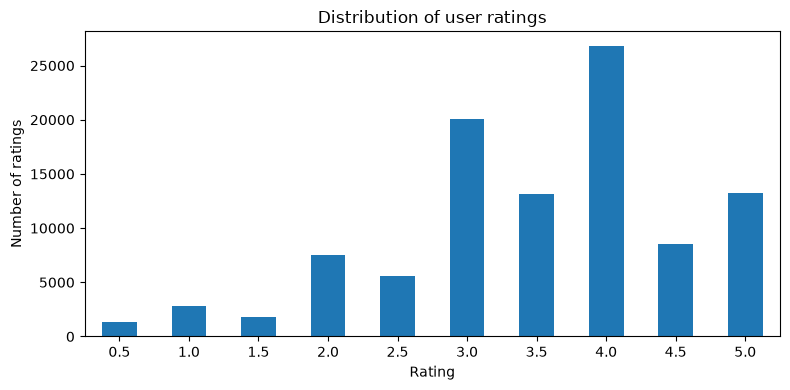

In [17]:
rating_counts = ratings["rating"].value_counts().sort_index()
ax = rating_counts.plot(kind="bar", figsize=(8, 4), rot=0,
                        title="Distribution of user ratings")
ax.set_xlabel("Rating")
ax.set_ylabel("Number of ratings")
plt.tight_layout()
plt.show()


## 5. روند زمانی ثبت امتیازها

`timestamp` به تاریخ UTC تبدیل می‌شود. تعداد امتیازهای ثبت‌شده در هر سال نمایش داده می‌شود تا گستره زمانی داده‌ها و تغییر حجم فعالیت در طول زمان مشخص شود.


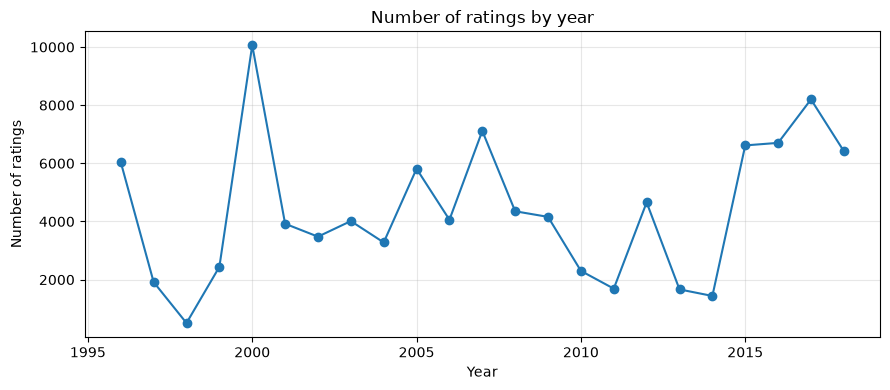

,rating_count
rated_at,
1996,6040
1997,1916
1998,507
1999,2439
2000,10061
2001,3922
2002,3478
2003,4014
2004,3279


In [18]:
ratings_time = ratings.copy()
ratings_time["rated_at"] = pd.to_datetime(
    ratings_time["timestamp"], unit="s", utc=True
)
yearly_ratings = ratings_time.groupby(
    ratings_time["rated_at"].dt.year
).size()

ax = yearly_ratings.plot(kind="line", marker="o", figsize=(9, 4),
                         title="Number of ratings by year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of ratings")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(yearly_ratings.rename("rating_count").to_frame())


## 6. میزان فعالیت کاربران و محبوبیت فیلم‌ها

تعداد امتیازهای هر کاربر و تعداد امتیازهای هر فیلم محاسبه می‌شود. معمولاً توزیع این دو متغیر نامتوازن است؛ تعداد کمی از کاربران یا فیلم‌ها ممکن است سهم بزرگی از تعاملات را داشته باشند.


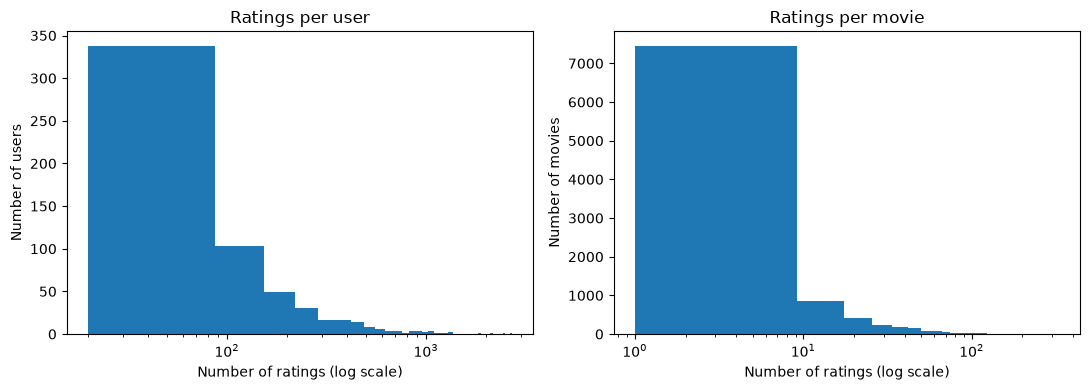

Median ratings per user: 70.5
Median ratings per movie: 3.0
Maximum ratings by one user: 2698
Maximum ratings for one movie: 329


In [19]:
user_activity = ratings.groupby("userId").size()
movie_activity = ratings.groupby("movieId").size()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(user_activity, bins=40)
axes[0].set_xscale("log")
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("Number of ratings (log scale)")
axes[0].set_ylabel("Number of users")

axes[1].hist(movie_activity, bins=40)
axes[1].set_xscale("log")
axes[1].set_title("Ratings per movie")
axes[1].set_xlabel("Number of ratings (log scale)")
axes[1].set_ylabel("Number of movies")

plt.tight_layout()
plt.show()

print("Median ratings per user:", user_activity.median())
print("Median ratings per movie:", movie_activity.median())
print("Maximum ratings by one user:", user_activity.max())
print("Maximum ratings for one movie:", movie_activity.max())


## 7. تحلیل ژانرها

هر فیلم می‌تواند چند ژانر داشته باشد؛ بنابراین ستون `genres` با جداکننده `|` به چند ردیف تبدیل می‌شود. سپس تعداد فیلم‌های هر ژانر و میانگین امتیازهای ثبت‌شده برای آن ژانر محاسبه می‌شود.


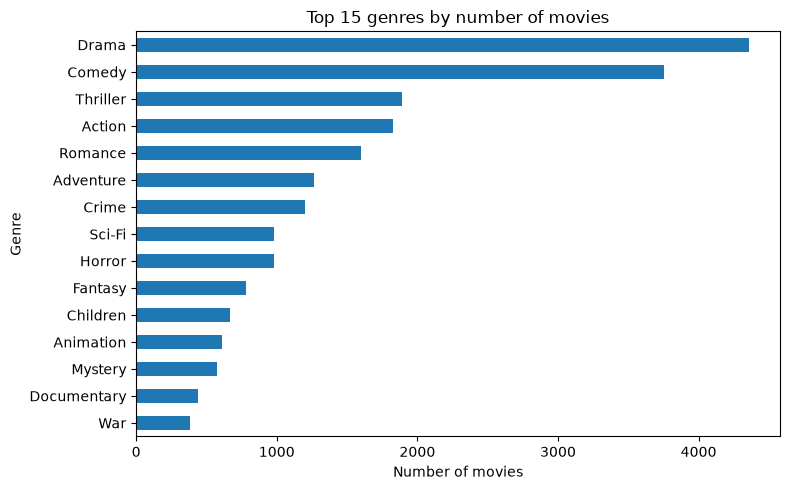

,movie_count,rating_count,mean_rating
genre,,,
Drama,4349,41928,3.66
Comedy,3753,39053,3.38
Action,1828,30635,3.45
Thriller,1889,26452,3.49
Adventure,1262,24161,3.51
Romance,1591,18124,3.51
Sci-Fi,980,17243,3.46
Crime,1196,16681,3.66
Fantasy,778,11834,3.49


In [20]:
genre_long = movies[["movieId", "genres"]].copy()
genre_long["genre"] = genre_long["genres"].fillna(
    "(no genres listed)"
).str.split("|")
genre_long = genre_long.explode("genre")

genre_movie_counts = (
    genre_long[["movieId", "genre"]]
    .drop_duplicates()
    .groupby("genre")["movieId"]
    .nunique()
    .sort_values(ascending=False)
)

ax = genre_movie_counts.head(15).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 15 genres by number of movies"
)
ax.set_xlabel("Number of movies")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.show()

genre_ratings = ratings.merge(
    genre_long[["movieId", "genre"]].drop_duplicates(),
    on="movieId",
    how="inner"
)
genre_score_summary = genre_ratings.groupby("genre").agg(
    movie_count=("movieId", "nunique"),
    rating_count=("rating", "size"),
    mean_rating=("rating", "mean"),
).sort_values("rating_count", ascending=False)

display(genre_score_summary.round(2).head(15))


## 8. فیلم‌های پرامتیاز و رابطه محبوبیت با میانگین امتیاز

برای جلوگیری از بالا آمدن فیلم‌هایی با فقط یک یا دو رأی، جدول فیلم‌های دارای بالاترین میانگین امتیاز با حداقل ۳۰ امتیاز جداگانه بررسی می‌شود. نمودار پراکندگی نیز تعداد امتیازها را با میانگین امتیاز هر فیلم مقایسه می‌کند.


10 most-rated movies:


,title,rating_count,mean_rating
314,Forrest Gump (1994),329,4.16
277,"Shawshank Redemption, The (1994)",317,4.43
257,Pulp Fiction (1994),307,4.20
510,"Silence of the Lambs, The (1991)",279,4.16
1938,"Matrix, The (1999)",278,4.19
224,Star Wars: Episode IV - A New Hope (1977),251,4.23
418,Jurassic Park (1993),238,3.75
97,Braveheart (1995),237,4.03
507,Terminator 2: Judgment Day (1991),224,3.97
461,Schindler's List (1993),220,4.22


10 highest-rated movies with at least 30 ratings:


,title,rating_count,mean_rating
277,"Shawshank Redemption, The (1994)",317,4.43
905,Lawrence of Arabia (1962),45,4.30
659,"Godfather, The (1972)",192,4.29
2224,Fight Club (1999),218,4.27
974,Cool Hand Luke (1967),57,4.27
602,Dr. Strangelove or: How I Learned to Stop Worr...,97,4.27
686,Rear Window (1954),84,4.26
921,"Godfather: Part II, The (1974)",129,4.26
6298,"Departed, The (2006)",107,4.25
913,Goodfellas (1990),126,4.25


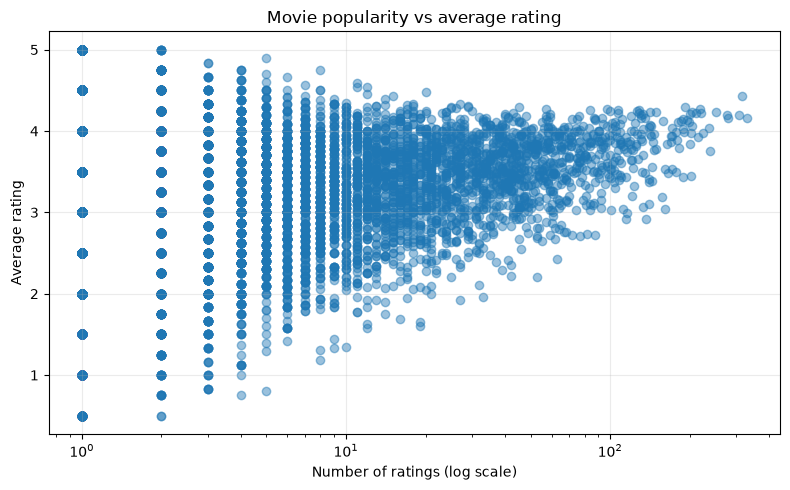

Spearman correlation (rating count vs mean rating): 0.04


In [21]:
movie_stats = ratings.groupby("movieId").agg(
    rating_count=("rating", "size"),
    mean_rating=("rating", "mean"),
    median_rating=("rating", "median"),
).reset_index()

movie_stats = movie_stats.merge(
    movies[["movieId", "title"]], on="movieId", how="left"
)

most_rated = movie_stats.sort_values(
    ["rating_count", "mean_rating"], ascending=[False, False]
).head(10)

best_rated = movie_stats[movie_stats["rating_count"] >= 30].sort_values(
    ["mean_rating", "rating_count"], ascending=[False, False]
).head(10)

print("10 most-rated movies:")
display(most_rated[["title", "rating_count", "mean_rating"]].round(2))

print("10 highest-rated movies with at least 30 ratings:")
display(best_rated[["title", "rating_count", "mean_rating"]].round(2))

plt.figure(figsize=(8, 5))
plt.scatter(movie_stats["rating_count"], movie_stats["mean_rating"], alpha=0.45)
plt.xscale("log")
plt.xlabel("Number of ratings (log scale)")
plt.ylabel("Average rating")
plt.title("Movie popularity vs average rating")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Spearman correlation (rating count vs mean rating):",
      round(movie_stats[["rating_count", "mean_rating"]].corr(
          method="spearman"
      ).iloc[0, 1], 3))


## 9. تنکی ماتریس کاربر-فیلم و جمع‌بندی عددی

در سیستم پیشنهاددهنده، بیشتر کاربران فقط به بخش کوچکی از کل فیلم‌ها امتیاز می‌دهند. نسبت تعاملات ثبت‌شده به تمام زوج‌های ممکن کاربر-فیلم، چگالی ماتریس و مکمل آن، تنکی (Sparsity) است.


In [22]:
n_users = ratings["userId"].nunique()
n_movies = ratings["movieId"].nunique()
n_interactions = len(ratings)
possible_pairs = n_users * n_movies
density = n_interactions / possible_pairs
sparsity = 1 - density

print(f"Users: {n_users:,}")
print(f"Movies: {n_movies:,}")
print(f"Observed ratings: {n_interactions:,}")
print(f"Possible user-movie pairs: {possible_pairs:,}")
print(f"Matrix density: {density:.4%}")
print(f"Matrix sparsity: {sparsity:.4%}")

print("\nTrain/test split:")
print("Train rows:", len(train))
print("Test rows:", len(test))
print("Train fraction:", round(len(train) / (len(train) + len(test)), 4))
print("Test fraction:", round(len(test) / (len(train) + len(test)), 4))


Users: 610
Movies: 9,724
Observed ratings: 100,836
Possible user-movie pairs: 5,931,640
Matrix density: 1.7000%
Matrix sparsity: 98.3000%

Train/test split:
Train rows: 80419
Test rows: 20417
Train fraction: 0.7975
Test fraction: 0.2025


## 10. نکات لازم برای گزارش نهایی

پس از اجرای همه سلول‌ها، گزارش کوتاه خود را با تکیه بر اعداد واقعی خروجی‌ها بنویسید. برای هر نمودار از الگوی «مشاهده، دلیل احتمالی، نتیجه برای پروژه» استفاده کنید.

مواردی که باید در گزارش پاسخ داده شوند:
1. آیا داده خام مقدار گمشده یا رکورد تکراری دارد؟ پاک‌سازی چه تغییری ایجاد کرده است؟
2. توزیع امتیازها به کدام سمت متمایل است؟ این موضوع چه اثری بر پیش‌بینی امتیاز دارد؟
3. آیا تعداد امتیازهای کاربران و فیلم‌ها متوازن است یا چند کاربر/فیلم بسیار فعال‌اند؟
4. کدام ژانرها بیشترین تعداد فیلم یا امتیاز را دارند؟ آیا محبوب‌ترین ژانر الزاماً بالاترین میانگین امتیاز را هم دارد؟
5. تنکی ماتریس کاربر-فیلم چقدر است و چرا برای پیشنهاددهنده چالش ایجاد می‌کند؟
6. جداسازی زمانی آموزش/آزمون چه کمکی به ارزیابی منصفانه‌تر می‌کند؟

**محدودیت داده:** MovieLens `ml-latest-small` شامل فیلم‌ها و امتیازهای کاربران است، نه کتاب‌ها. در نسخه فعلی پروژه، دامنه داده به پیشنهاد فیلم محدود شده است. داده‌ها نیز مربوط به بازه تاریخی مجموعه MovieLens هستند و نماینده همه کاربران یا فیلم‌های جدید نیستند.

**منبع داده:** MovieLens / GroupLens. برای استناد علمی می‌توان از مقاله Harper, F. M., & Konstan, J. A. (2015), *The MovieLens Datasets: History and Context* استفاده کرد.
